# RutaPro · Notebook 08: El mismo protocolo sobre datos reales (MOOCCubeX)

**Qué es.** RutaPro usa estudiantes e interacciones **simulados**. Este notebook repite el protocolo (particiones temporales, baselines, intervalos, pruebas pareadas, cold start, sesgos) sobre **inscripciones reales** de estudiantes en cursos de XuetangX (plataforma MOOC china), publicadas en **MOOCCubeX** (Tsinghua, CIKM 2021).

**Por qué esta versión.** En una primera ejecución con *MOOCCube v1* (199 199 estudiantes) los estudiantes no traían ningún atributo (ni género, ni escuela, ni año de nacimiento), y por eso LightFM y la popularidad por segmento quedaron sin su insumo principal: la comparación no era justa para ellos. **MOOCCubeX sí trae `gender`, `school` y `year_of_birth`** (3 330 294 estudiantes), así que este notebook usa esa versión y mide además cuánto aportan esos atributos.

> **Versión 2 (corregida).** Respecto de la primera ejecución con MOOCCubeX, esta versión cambia cuatro cosas:
> 1. **Tolerancia relativa.** La regla de parsimonia usaba una tolerancia *absoluta* de 0.01 heredada de RutaPro (donde el NDCG era ~0.2). Aquí el NDCG ronda 0.05, así que 0.01 equivale a un 20 % y dejaba pasar cualquier configuración: se elegía siempre la más simple (por ejemplo LightFM con solo 32 factores y 50 épocas) y un segmento que no era el mejor en validación. Ahora la tolerancia es del 5 % *del mejor*.
> 2. **Segmento y rival correctos.** Se prueban escuela, género y ambos; se agrega siempre **Pop. por género** como rival explícito en las tablas, porque el código de género era justamente la señal del cold start.
> 3. **Nuevo modelo: LightFM + KNN.** Fusión de los rankings de LightFM y de un KNN (variante y peso ajustados en validación). Se compara con sus dos componentes.
> 4. **Se retiró la columna "cambio por tener atributos"** de la tabla de comparación: restaba valores de muestras y versiones distintas y no medía el efecto de los atributos. Ese efecto lo mide la **ablación**.

> **Los resultados los produce quien lo ejecute.** No hay cifras de MOOCCubeX en este notebook; la sección 12 trae una guía de qué concluir según lo que salga, fijada antes de ver resultados.

## Qué cambia y qué no respecto de RutaPro

| | RutaPro (simulado) | MOOCCubeX (real) |
|---|---|---|
| Interacción positiva | Inscripción | **Inscripción** (`course_order`, con su fecha en `enroll_time`) |
| Particiones, métricas, intervalos, Holm | Igual | **Igual** (mismo código) |
| Atributos del estudiante | Carrera, nivel, idioma, objetivo, intereses | **Género (código), escuela (texto) y año de nacimiento**: muchos vacíos y valores imposibles que se limpian |
| Atributos del curso | Categoría, nivel, idioma, plataforma, duración | **Disciplina, escuela que lo dicta y tamaño (n.º de recursos)**; texto en chino |
| Reglas de idioma y nivel | Sí | **No aplican** (no existen esos campos) |
| Oráculo (techo) | Sí | **No existe** (no hay simulador) |

## Cómo se consiguen los datos: automático

La primera celda de configuración **descarga solo lo necesario** de `lfs.aminer.cn` (≈ 820 MB, entre 4 y 8 minutos): `school.json`, `course.json`, `user.json` y, si existen, `course-field.json` y `course-school.txt`. Es **idempotente**: si ya están completos no los vuelve a bajar, y si una descarga quedó a medias la repite. Tampoco toca nada de MOOCCube v1: los guarda en `01_Datos/mooccubex_x`.

Si ya los tienes (por ejemplo en `/content/entities/`), el notebook los **encuentra solo** y comprueba que traigan `gender` / `school` / `year_of_birth`. Si prefieres indicar la carpeta: `RUTA_DATOS = "/content"`.

**Qué hace con `user.json` (3.3 millones de estudiantes):** lo lee en *streaming* y toma una **muestra aleatoria** del 5 % de las líneas (`FRACCION_USUARIOS`), no las primeras filas: en MOOCCubeX las primeras filas son del personal de Tsinghua y sesgarían todo. Con eso quedan ≈ 160 000 estudiantes, de los que se muestrean `N_USUARIOS`.

**Limpieza de atributos** (los datos reales vienen sucios): el año de nacimiento solo se acepta entre 1940 y 2008 (se vieron valores como 6558 o 2015); la escuela vacía pasa a `sin_dato`; el género conserva su código (`g0`, `g1`, `g2`) **sin interpretarlo**, porque la documentación no dice qué significa el 0.

**Tiempo de ejecución:** descarga 4–8 min + lectura 1–3 min + 15–30 min de análisis con `N_USUARIOS = 5000`. Si es mucho, baja `N_USUARIOS` a 2000.

**Privacidad y licencia.** `user.json` incluye un campo `name`: el código **no lo lee**; no subas esos archivos a GitHub. Revisa los términos del repositorio y cita a Yu et al. (2021, CIKM, *MOOCCubeX*).

### En Google Colab

Sube `rutapro_rec.py`, `rutapro_extra.py`, `rutapro_sim.py` y `rutapro_mooc.py` a la carpeta desde la que ejecutas (por ejemplo `/content`) y compila LightFM con la celda de los notebooks 02 y 03 (≈ 2 minutos, en cada sesión). Después ejecuta desde la primera celda: no hace falta mover archivos.

### Si algo no cuadra

Ejecuta la celda de diagnóstico (`mc.diagnosticar`): muestra qué archivos encontró y un par de registros. El código resuelve identificadores `C_123` frente a `123` y avisa si los cursos de `user.json` no coinciden con `course.json`.

In [1]:
import os, sys, subprocess
from google.colab import drive

NECESITA_LIGHTFM = True

# 1) Conectar el Drive y entrar a la carpeta del proyecto
drive.mount('/content/drive')
PROY = "/content/drive/MyDrive/RutaPro"
os.chdir(PROY + "/02_Notebooks")
print("Carpeta actual:", os.getcwd())

# 2) Comprobar que están los archivos imprescindibles
faltan = [f for f in ["rutapro_rec.py", "rutapro_sim.py", "rutapro_extra.py", "rutapro_mooc.py",
                      "resultados/hiperparametros.json", "../01_Datos/cursos.csv",
                      "../01_Datos/pares_usuario_curso.csv"] if not os.path.exists(f)]
print("Archivos que faltan:", faltan if faltan else "ninguno, todo en su sitio")

# 3) LightFM: usa la copia compilada en el Drive; si no existe, la compila (≈ 2 min) y la guarda
def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-1500:], r.stderr[-1500:])
        raise RuntimeError("Falló: " + cmd[:70])

if NECESITA_LIGHTFM:
    LF = PROY + "/lightfm_src"
    if not os.path.exists(LF + "/lightfm"):
        print("Compilando LightFM, un momento...")
        sh("pip install -q cython")
        sh("rm -rf /content/lightfm_src && git clone -q --depth 1 https://github.com/lyst/lightfm.git /content/lightfm_src")
        p = "/content/lightfm_src/setup.py"
        s = open(p).read()
        s = s.replace("compiler_directives={'language_level' : \"3\"}",
                      "compiler_directives={'language_level': \"3\", 'legacy_implicit_noexcept': True}").replace("-march=native", "-O2")
        open(p, "w").write(s)
        sh("cd /content/lightfm_src && python setup.py cythonize -q && python setup.py build_ext --inplace -q")
        sh("rm -rf '" + LF + "' && cp -r /content/lightfm_src '" + LF + "'")
    sys.path.insert(0, LF)
    import lightfm
    print("LightFM", lightfm.__version__)

Mounted at /content/drive
Carpeta actual: /content/drive/.shortcut-targets-by-id/1Z5XbASVfSPtFWsbbN2qhK0vGCB8tiPaJ/RutaPro/02_Notebooks
Archivos que faltan: ninguno, todo en su sitio
LightFM 1.17


In [2]:
RUTA_DATOS = None             # None = buscar/descargar automáticamente. Si ya los tienes: RUTA_DATOS = "/content" (carpeta que contiene entities/)
DESCARGAR = True              # True = descarga lo que falte (≈ 820 MB la primera vez). False = no toca la red
USAR_SINTETICO = False        # True = datos inventados con el mismo formato, SOLO para probar que el código corre
N_USUARIOS = 5000             # estudiantes de la muestra de análisis (KNN usuario usa una matriz N x N: no pases de ~8 000)
FRACCION_USUARIOS = 0.05      # fracción ALEATORIA de las líneas de user.json que se lee (0.05 ≈ 166 000 estudiantes de 3.3 millones)
MAX_LINEAS = None             # None = recorre todo user.json (con muestreo aleatorio). No uses las primeras líneas: no son aleatorias
MIN_INSCRIPCIONES = 3         # mínimo de inscripciones por estudiante (necesario para particionar)
MIN_POP_CURSO = 20            # mínimo de inscripciones por curso en la muestra (k-core)
SOLO_CON_PERFIL = False       # True = analiza solo estudiantes con escuela o cohorte informada (la sección 10 compara ambas poblaciones)
TOL_REL = 0.05                # tolerancia RELATIVA (5 % del mejor NDCG) de la regla de parsimonia. La versión anterior usaba 0.01 absoluta: ver sección 3
INCLUIR_HIBRIDO = True        # True = agrega el modelo híbrido LightFM + KNN (fusión de rankings, con su peso ajustado en validación)

In [3]:
import json, warnings, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
warnings.filterwarnings("ignore")

import rutapro_rec as rr
import rutapro_extra as ex
import rutapro_mooc as mc

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#9a9890"
VIOLETA = "#7a5cc7"
TXT, TXT2 = "#0b0b0b", "#52514e"
mpl.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d4d3cd", "axes.labelcolor": TXT2, "xtick.color": TXT2, "ytick.color": TXT2,
    "text.color": TXT, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ebeae6",
    "axes.axisbelow": True, "font.size": 10, "figure.dpi": 110,
})
BASE = rr.ruta_base(); DATA = BASE / "01_Datos"
FIG = BASE / "04_Informe" / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
RES = BASE / "02_Notebooks" / "resultados_mooc"; RES.mkdir(parents=True, exist_ok=True)
def guardar(fig, n): fig.savefig(FIG / f"{n}.png", dpi=160, bbox_inches="tight")

DIR_DESTINO = DATA / "mooccubex_x"          # carpeta NUEVA: no se mezcla con MOOCCube v1

def _es_mooccubex(d):
    # True si en d hay un user.json con gender / school / year_of_birth (MOOCCubeX). Descarta MOOCCube v1.
    try:
        return bool(mc._ruta(d, "entities/user.json", "user.json")) and mc.tiene_atributos(d)
    except Exception:
        return False

if USAR_SINTETICO:
    DIR_MOOC = DATA / "mooccubex_sintetico" if DATA.exists() else Path("/tmp/mooccubex_sintetico")
    mc.generar_sintetico(DIR_MOOC, n_usuarios=3000, n_cursos=200)
    print("*** DATOS SINTÉTICOS: los resultados de este notebook NO significan nada ***")
else:
    if RUTA_DATOS:
        DIR_MOOC = Path(RUTA_DATOS)
    else:                   # busca MOOCCubeX ya descargado (incluye /content en Colab); si no hay, usa la carpeta de descarga
        candidatas = list(dict.fromkeys([DIR_DESTINO, BASE, Path.cwd(), Path("/content")]))
        DIR_MOOC = next((d for d in candidatas if d.exists() and _es_mooccubex(d)), DIR_DESTINO)
    if DESCARGAR:
        print("Comprobando / descargando MOOCCubeX en", DIR_MOOC.resolve())
        try:
            mc.descargar_mooccubex(DIR_MOOC)
        except Exception as e:
            print("NO SE PUDO DESCARGAR:", e)
            print("Descarga a mano course.json y user.json (enlaces en el README de github.com/THU-KEG/MOOCCubeX), ponlos en", DIR_MOOC / "entities",
                  "y vuelve a ejecutar esta celda con DESCARGAR = False.")
    DIR_MOOC = mc.raiz_datos(DIR_MOOC)

HAY_DATOS = bool(mc._ruta(DIR_MOOC, "entities/user.json", "user.json") and mc._ruta(DIR_MOOC, "entities/course.json", "course.json"))
if HAY_DATOS:
    print("Datos encontrados en", DIR_MOOC.resolve())
    if not USAR_SINTETICO and not mc.tiene_atributos(DIR_MOOC):
        print("AVISO: este user.json NO trae gender / school / year_of_birth: parece MOOCCube v1 (sin atributos). "
              "Los resultados serán los de la comparación sin perfil. Para la versión con atributos descarga MOOCCubeX (DESCARGAR = True y otra carpeta).")
else:
    print("No se encontraron course.json y user.json en", DIR_MOOC.resolve())
    print("Pon DESCARGAR = True, o la ruta a mano (por ejemplo RUTA_DATOS = '/content'). El resto de las celdas se omite sin error.")

Comprobando / descargando MOOCCubeX en /content/drive/.shortcut-targets-by-id/1Z5XbASVfSPtFWsbbN2qhK0vGCB8tiPaJ/RutaPro/01_Datos/mooccubex_x
descargando entities/school.json ...
descargando relations/course-field.json ...
descargando relations/course-school.txt ...
descargando entities/course.json ...
descargando entities/user.json  (769 MB: unos 5 minutos, no interrumpas) ...
Datos encontrados en /content/drive/.shortcut-targets-by-id/1Z5XbASVfSPtFWsbbN2qhK0vGCB8tiPaJ/RutaPro/01_Datos/mooccubex_x


### Diagnóstico (ejecútalo si algo falla)

Muestra qué archivos encontró y un par de registros de cada uno, para ver si el esquema es el esperado.

In [4]:
mc.diagnosticar(DIR_MOOC)

Carpeta: /content/drive/.shortcut-targets-by-id/1Z5XbASVfSPtFWsbbN2qhK0vGCB8tiPaJ/RutaPro/01_Datos/mooccubex_x
  entities/course.json  (44.7 MB)
  entities/school.json  (0.6 MB)
  entities/user.json  (806.8 MB)
  relations/course-field.json  (0.1 MB)
  relations/course-school.txt  (0.1 MB)

--- course.json: /content/drive/.shortcut-targets-by-id/1Z5XbASVfSPtFWsbbN2qhK0vGCB8tiPaJ/RutaPro/01_Datos/mooccubex_x/entities/course.json
  registro 0: {'id': 'C_584313', 'name': '《资治通鉴》导读', 'field': ['历史学', '中国语言文学'], 'prerequisites': '', 'about': '通过老师导读，同学们可深入这一经典文本内部，得以纵览千年历史，提升国学素养，体味人生智慧。', 'resource': "[{'titles': ['第一课 导论与三家分晋', '导论', '导论'], 'resource_id': 'V_8..."}
  registro 1: {'id': 'C_584329', 'name': '微积分——极限理论与一元函数', 'field': ['应用经济学', '数学', '物理学', '理论经济学'], 'prerequisites': '', 'about': '本课程是理工科的一门数学基础课，系统、全面地介绍了一元函数微积分学。课程既保持了数学的严谨和抽象的特点，也注意了数学概念...', 'resource': "[{'titles': ['序言', '序言', '序言'], 'resource_id': 'V_1350', 'ch..."}

--- user.json: /content/drive/.shortcut-targets-by-

## 1. Carga y descripción de los datos reales

Se leen **todos** los cursos y una **muestra aleatoria** (`FRACCION_USUARIOS`) de las líneas de `user.json` en *streaming* (el archivo pesa 770 MB y tiene 3.3 millones de estudiantes). Leer solo las primeras filas sería un error: en MOOCCubeX son del personal de Tsinghua (escuela "清华大学") y no representan a los estudiantes.

In [5]:
if HAY_DATOS:
    t0 = time.time()
    cursos_raw = mc.cargar_cursos(DIR_MOOC)
    usuarios_raw, ins_raw = mc.cargar_inscripciones(DIR_MOOC, set(cursos_raw.course_id), max_lineas=MAX_LINEAS,
                                                    fraccion=FRACCION_USUARIOS, seed=0)
    print(f"Lectura: {time.time() - t0:.0f} s | cursos: {len(cursos_raw):,} | estudiantes con inscripciones: {len(usuarios_raw):,} | inscripciones: {len(ins_raw):,}")
    act = ins_raw.groupby("user_id").size()
    pop = ins_raw.groupby("course_id").size().sort_values()
    x = pop.values.astype(float); n = len(x)
    gini = 2 * np.sum(np.arange(1, n + 1) * x) / (n * x.sum()) - (n + 1) / n
    desc = pd.Series({
        "estudiantes": len(usuarios_raw), "cursos": len(cursos_raw), "inscripciones": len(ins_raw),
        "inscripciones por estudiante (mediana)": act.median(), "inscripciones por estudiante (media)": act.mean(),
        "estudiantes con >= 3 inscripciones (%)": 100 * (act >= 3).mean(),
        "Gini de inscripciones por curso": gini,
        "% de inscripciones en el 20 % de cursos más populares": 100 * pop.sort_values(ascending=False).head(int(np.ceil(0.2 * n))).sum() / pop.sum(),
        "fecha mínima": str(ins_raw.timestamp.min().date()), "fecha máxima": str(ins_raw.timestamp.max().date()),
        "disciplinas distintas": cursos_raw.campos.str.split(";").str[0].nunique(),
    })
    desc.to_frame("valor").to_csv(RES / "descripcion_datos_reales.csv")
    display(desc.map(lambda v: round(float(v), 2) if isinstance(v, (int, float, np.number)) else v).to_frame("valor"))

Referencias a cursos en user.json: 589,960 | resueltas contra el catalogo: 575,557 (97.6 %)
Lectura: 16 s | cursos: 3,781 | estudiantes con inscripciones: 160,495 | inscripciones: 575,557


,valor
estudiantes,160495.0
cursos,3781.0
inscripciones,575557.0
inscripciones por estudiante (mediana),1.0
inscripciones por estudiante (media),3.59
estudiantes con >= 3 inscripciones (%),21.22
Gini de inscripciones por curso,0.7
% de inscripciones en el 20 % de cursos más populares,72.81
fecha mínima,2019-05-14
fecha máxima,2020-12-08


### Qué tan informado está el perfil

Después de limpiar valores imposibles. **Este es el dato clave para juzgar si la comparación es justa para LightFM y para la popularidad por segmento**: si casi nadie tiene perfil, esos modelos siguen con poco insumo, y la sección 10 mide el efecto restringiendo a quienes sí lo tienen.

In [6]:
if HAY_DATOS:
    rep = mc.resumen_atributos(usuarios_raw)
    rep.round(1).to_frame("valor").to_csv(RES / "atributos_informados.csv")
    display(rep.round(1).to_frame("valor"))
    print("Género (código, sin interpretar):", usuarios_raw.genero.value_counts().to_dict())
    print("Cohorte de nacimiento:", usuarios_raw.edad_grupo.value_counts().to_dict())
    print("Escuelas más frecuentes:", usuarios_raw.escuela.value_counts().head(8).to_dict())
    if rep["% con escuela o cohorte informada"] < 5:
        print("AVISO: menos del 5 % de los estudiantes tiene escuela o cohorte. Los atributos casi no aportarán: revisa que no estés usando MOOCCube v1.")

,valor
estudiantes,160495.0
% con escuela informada,34.7
% con año de nacimiento plausible (1940-2008),0.0
% con género distinto de 'sin_dato',100.0
% con escuela o cohorte informada,34.7


Género (código, sin interpretar): {'g0': 58694, 'g1': 51659, 'g2': 50137, 'sin_dato': 5}
Cohorte de nacimiento: {'sin_dato': 160441, '1990-1999': 37, '1980-1989': 10, '<1980': 5, '2000+': 2}
Escuelas más frecuentes: {'sin_dato': 104804, '清华大学': 819, '昆明理工大学': 778, '湖南大学': 646, '河北工业大学': 490, '河南工业大学': 475, '湖北科技学院': 467, '广西科技大学': 444}


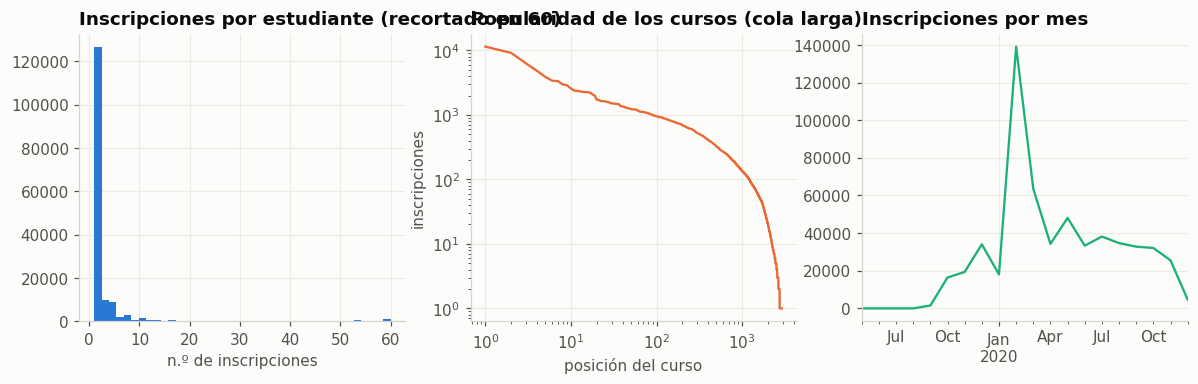

In [7]:
if HAY_DATOS:
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
    axes[0].hist(act.clip(upper=60), bins=40, color=AZUL); axes[0].set_title("Inscripciones por estudiante (recortado en 60)"); axes[0].set_xlabel("n.º de inscripciones")
    axes[1].plot(np.arange(1, n + 1), pop.sort_values(ascending=False).values, color=NARANJA); axes[1].set_yscale("log"); axes[1].set_xscale("log")
    axes[1].set_title("Popularidad de los cursos (cola larga)"); axes[1].set_xlabel("posición del curso"); axes[1].set_ylabel("inscripciones")
    ins_raw.set_index("timestamp").resample("MS").size().plot(ax=axes[2], color=AQUA); axes[2].set_title("Inscripciones por mes"); axes[2].set_xlabel("")
    guardar(fig, "26_mooc_eda"); plt.show()

## 2. Preparación documentada

Pasos (todos visibles en `mc.preparar`): muestra aleatoria de estudiantes con al menos 3 inscripciones; **k-core** (se eliminan cursos con pocas inscripciones y luego estudiantes con pocas, hasta que no cambie nada); escuelas con pocos estudiantes se agrupan en "otra". Se reporta cuánto se pierde. El resultado tiene el formato de RutaPro (`usuarios`, `cursos`, `interacciones` con `evento = inscripcion`), así que se reutilizan las particiones, métricas y modelos sin cambios.

In [8]:
if HAY_DATOS:
    usu, cur, inter, resumen = mc.preparar(usuarios_raw, ins_raw, cursos_raw, n_usuarios=N_USUARIOS, seed=0,
                                           min_pop_curso=MIN_POP_CURSO, min_inscripciones=MIN_INSCRIPCIONES,
                                           solo_con_perfil=SOLO_CON_PERFIL)
    display(pd.Series(resumen).map(lambda v: round(float(v), 2) if isinstance(v, (int, float, np.number)) and not isinstance(v, bool) else v).to_frame("valor"))
    print("Perfil en la muestra de análisis:", mc.resumen_atributos(usu).round(1).to_dict())
    mc.instalar_adaptadores()      # rutapro_rec usa ahora los atributos de MOOCCube (género, escuela, cohorte; disciplina, escuela, tamaño)
    perfil_de = usu.set_index("user_id").to_dict("index")
    pares = ex.construir_pares(inter)
    print("Atributos del estudiante:", rr.atributos_usuario(usu.iloc[0]))
    print("Atributos del curso:", rr.atributos_curso(cur.iloc[0]))
    for col, nom in [("particion", "por estudiante (esquema B)"), ("particion_global", "corte global (esquema A)")]:
        tr = pares[pares[col].isin(["train", "valid"])]; te = pares[(pares[col] == "test") & (pares.positivo == 1)]
        print(f"Evaluables en prueba, {nom}: {len(set(te.user_id) & set(tr[tr.positivo == 1].user_id)):,}")

,valor
usuarios con >= min inscripciones (antes de muestrear),34051.0
estudiantes en la muestra final,3714.0
cursos finales,720.0
inscripciones finales,49228.0
solo con perfil,False
% de inscripciones conservadas (de la lectura),8.55
dispersion de la matriz (%),98.16


Perfil en la muestra de análisis: {'estudiantes': 3714.0, '% con escuela informada': 23.1, '% con año de nacimiento plausible (1940-2008)': 0.0, "% con género distinto de 'sin_dato'": 100.0, '% con escuela o cohorte informada': 23.1}
Atributos del estudiante: ['genero:g1', 'escuela:sin_dato', 'edad:sin_dato']
Atributos del curso: ['campo:艺术学', 'escuela_curso:清华大学', 'tamano:grande']
Evaluables en prueba, por estudiante (esquema B): 3,714
Evaluables en prueba, corte global (esquema A): 1,019


In [9]:
if HAY_DATOS:
    # Con datos reales y muchos estudiantes el corte global (sin fuga entre estudiantes) es viable: es el protocolo principal
    tr = pares[pares.particion_global.isin(["train", "valid"])]; te = pares[(pares.particion_global == "test") & (pares.positivo == 1)]
    n_glob = len(set(te.user_id) & set(tr[tr.positivo == 1].user_id))
    ESQ = "global" if n_glob >= 300 else "usuario"
    print(f"Protocolo principal: corte {'GLOBAL' if ESQ == 'global' else 'POR ESTUDIANTE'} ({n_glob:,} evaluables con corte global)")
    val = rr.construir_particion(cur, usu, pares, etapa="validacion", esquema=ESQ)
    prueba = rr.construir_particion(cur, usu, pares, etapa="prueba", esquema=ESQ)
    eleg = prueba.usuarios_elegibles()
    print(f"Estudiantes evaluables en prueba: {len(eleg):,}")

Protocolo principal: corte GLOBAL (1,019 evaluables con corte global)
Estudiantes evaluables en prueba: 1,019


## 3. Ajuste de hiperparámetros (solo validación)

NDCG@10 en validación con regla de parsimonia: entre las configuraciones cuyo NDCG está a menos de `TOL_REL` (5 %) del mejor, se elige la más simple. **Tolerancia relativa, no absoluta**: con NDCG ≈ 0.05, una tolerancia de 0.01 (la de la versión anterior) es un 20 % del mejor y deja pasar casi cualquier configuración.

El texto de los cursos está en chino: el contenido tokeniza cada carácter y usa unigramas y bigramas. Como los estudiantes no tienen texto, el contenido usa solo su historial.

**Segmento** del baseline "popularidad por segmento": se elige entre escuela, género y ambos.

**Híbrido LightFM + KNN.** Fusión por rango recíproco: `puntaje = w / (k + rango_LightFM) + (1 − w) / (k + rango_KNN)`. Se fusionan *rangos* y no puntajes porque los de LightFM (sin escala) y los de KNN (similitudes con muchos ceros) no son comparables. La **variante de KNN** (usuario o ítem) y el **peso `w`** se eligen en validación; `k = 20` es fijo. Para un estudiante sin historial el híbrido usaría solo LightFM, porque KNN no puede atender el cold start.

In [10]:
!pip install -q cython
!git clone -q --depth 1 https://github.com/lyst/lightfm.git /content/lightfm_src
!sed -i "s/compiler_directives={'language_level' : \"3\"}/compiler_directives={'language_level': \"3\", 'legacy_implicit_noexcept': True}/" /content/lightfm_src/setup.py
!sed -i 's/-march=native/-O2/' /content/lightfm_src/setup.py
!cd /content/lightfm_src && python setup.py cythonize -q && python setup.py build_ext --inplace -q
import sys; sys.path.insert(0, "/content/lightfm_src")
import lightfm; print("LightFM", lightfm.__version__)

/usr/local/lib/python3.13/dist-packages/setuptools/dist.py:599: SetuptoolsDeprecationWarning: Invalid dash-separated key 'description-file' in 'metadata' (setup.cfg), please use the underscore name 'description_file' instead.
!!

        ********************************************************************************
        Usage of dash-separated 'description-file' will not be supported in future
        versions. Please use the underscore name 'description_file' instead.


        Available configuration options are listed in:
        https://setuptools.pypa.io/en/latest/userguide/declarative_config.html

        This deprecation is overdue, please update your project and remove deprecated
        calls to avoid build errors in the future.

        See https://github.com/pypa/setuptools/discussions/5011 for details.
        ********************************************************************************

!!
  opt = self._enforce_underscore(opt, section)
/usr/local/lib/python3.13/dis

In [11]:
if HAY_DATOS:
    filas = []
    for cols in [("escuela",), ("genero",), ("escuela", "genero")]:
        for m in [0, 5, 20, 50]:
            r = rr.evaluar(ex.PopularidadSegmento(cols, m).fit(val), val).loc[10]
            filas.append({"segmento": " + ".join(cols), "n_cols": len(cols), "m": m, **r[["ndcg", "hit_rate", "cobertura"]]})
    grid_seg = pd.DataFrame(filas)
    cand = grid_seg[grid_seg.ndcg >= grid_seg.ndcg.max() * (1 - TOL_REL)]
    mejor = cand.sort_values(["n_cols", "m", "ndcg"], ascending=[True, True, False]).iloc[0]     # parsimonia; a igualdad, el de mayor NDCG
    SEG = tuple(mejor.segmento.split(" + "))
    grid_seg.to_csv(RES / "grid_segmento.csv", index=False)
    display(grid_seg.sort_values("ndcg", ascending=False).head(8).round(3))
    ndcg_pop_val = rr.evaluar(rr.Popularidad().fit(val), val).loc[10, "ndcg"]
    print(f"Segmento elegido (parsimonia, tolerancia relativa {TOL_REL:.0%}):", SEG, "| NDCG@10 en validación:", round(mejor.ndcg, 3),
          "| popularidad global:", round(ndcg_pop_val, 3), "| mejor segmento posible:", grid_seg.loc[grid_seg.ndcg.idxmax(), "segmento"], round(grid_seg.ndcg.max(), 3))
    hp = ex.ajustar_hiperparametros(cur, usu, pares, esquema=ESQ, seg_cols=SEG, alphas_cont=(0.0,), ngram_cont=(1, 2),
                                    comps=(32, 64, 128), epocas=(50, 100, 200), tol_rel=TOL_REL, con_blend=INCLUIR_HIBRIDO)
    json.dump({"segmento": SEG, "tolerancia_relativa": TOL_REL, **hp}, open(RES / "hiperparametros_mooc.json", "w"), indent=1, ensure_ascii=False)
    print("Hiperparámetros:", {k_: v for k_, v in hp.items() if k_ != "blend_rejilla"})
    if hp.get("blend"):
        print("Híbrido LightFM + KNN en validación (NDCG@10 por variante de KNN y peso w de LightFM):")
        display(pd.DataFrame(hp["blend_rejilla"]).pivot(index="w", columns="variante", values="ndcg").round(4))

,segmento,n_cols,m,ndcg,hit_rate,cobertura
6,genero,1,20,0.044,0.268,0.065
7,genero,1,50,0.044,0.268,0.065
5,genero,1,5,0.044,0.268,0.065
4,genero,1,0,0.042,0.245,0.065
9,escuela + genero,2,5,0.042,0.241,0.104
10,escuela + genero,2,20,0.042,0.241,0.104
11,escuela + genero,2,50,0.042,0.241,0.104
8,escuela + genero,2,0,0.041,0.240,0.110


Segmento elegido (parsimonia, tolerancia relativa 5%): ('genero',) | NDCG@10 en validación: 0.042 | popularidad global: 0.036 | mejor segmento posible: genero 0.044
Hiperparámetros: {'seg_m': 0.0, 'cont_alpha': 0.0, 'knn_u_k': 50, 'knn_i_k': 20, 'lfm': {'no_components': 64, 'loss': 'warp', 'epochs': 50}, 'blend': {'variante': 'item', 'w': 0.5, 'k_rrf': 20}}
Híbrido LightFM + KNN en validación (NDCG@10 por variante de KNN y peso w de LightFM):


variante,item,usuario
w,,
0.25,0.0665,0.0642
0.50,0.0716,0.0628
0.75,0.0653,0.0615


## 4. Evaluación en prueba con intervalos de confianza

Entrenamiento + validación, una sola evaluación en prueba. Los modelos estocásticos (Aleatorio, LightFM) se promedian por estudiante entre semillas. **No hay reglas de negocio ni oráculo.**

In [12]:
if HAY_DATOS:
    fab_lfm = lambda s: rr.LightFMHibrido(**hp["lfm"], seed=s)
    pop = rr.Popularidad().fit(prueba)
    seg = ex.PopularidadSegmento(SEG, hp["seg_m"]).fit(prueba)
    cont = rr.ContenidoTFIDF(ngram=(1, 2), alpha_perfil=hp["cont_alpha"]).fit(prueba)
    knn_u = rr.KNNColaborativo(k=hp["knn_u_k"], variante="usuario").fit(prueba)
    knn_i = rr.KNNColaborativo(k=hp["knn_i_k"], variante="item").fit(prueba)
    lfm42 = fab_lfm(42).fit(prueba)

    dets, cob, recs = {}, {}, {}
    def correr(nombre, modelo, ks=(5, 10)):
        res, det, r = rr.evaluar(modelo, prueba, ks=ks, devolver_detalle=True)
        dets[nombre], cob[nombre], recs[nombre] = det, res["cobertura"].to_dict(), r
    dets["Aleatorio"], r_a = ex.evaluar_semillas(lambda s: ex.Aleatorio(s), prueba, semillas=range(10))
    cob["Aleatorio"] = r_a.groupby("K").cobertura.mean().to_dict()
    correr("Popularidad (global)", pop)
    correr("Pop. por segmento", seg)
    if SEG != ("genero",):                      # rival explícito: la señal del cold start era el código de género
        correr("Pop. por género", ex.PopularidadSegmento(("genero",), hp["seg_m"]).fit(prueba))
    correr("Contenido (TF-IDF)", cont)
    correr("KNN usuario", knn_u)
    correr("KNN ítem", knn_i)
    dets["LightFM híbrido"], r_l = ex.evaluar_semillas(fab_lfm, prueba, semillas=[42, 43, 44, 45, 46])
    cob["LightFM híbrido"] = r_l.groupby("K").cobertura.mean().to_dict()
    recs["LightFM híbrido"] = rr.evaluar(lfm42, prueba, ks=(10,), devolver_detalle=True)[2]
    HIB = bool(hp.get("blend"))
    if HIB:                                     # híbrido LightFM + KNN (fusión de rankings)
        var_b, w_b, k_b = hp["blend"]["variante"], hp["blend"]["w"], hp["blend"].get("k_rrf", 20)
        k_knn = hp["knn_u_k"] if var_b == "usuario" else hp["knn_i_k"]
        fab_hib = lambda s: ex.MezclaRRF(fab_lfm(s), rr.KNNColaborativo(k=k_knn, variante=var_b), w=w_b, k=k_b)
        dets["LightFM + KNN"], r_h = ex.evaluar_semillas(fab_hib, prueba, semillas=[42, 43, 44, 45, 46])
        cob["LightFM + KNN"] = r_h.groupby("K").cobertura.mean().to_dict()
        recs["LightFM + KNN"] = rr.evaluar(ex.MezclaRRF(lfm42, knn_u if var_b == "usuario" else knn_i, w=w_b, k=k_b, preajustados=True).fit(prueba),
                                           prueba, ks=(10,), devolver_detalle=True)[2]
        print(f"Híbrido: KNN {var_b}, peso de LightFM w = {w_b}, k_rrf = {k_b}")
    orden = (["Aleatorio", "Popularidad (global)", "Pop. por segmento"] + (["Pop. por género"] if "Pop. por género" in dets else [])
             + ["Contenido (TF-IDF)", "KNN usuario", "KNN ítem", "LightFM híbrido"] + (["LightFM + KNN"] if HIB else []))
    dets = {n: dets[n] for n in orden}
    def tabla(K):
        t = ex.tabla_con_ic(dets, K=K)
        t["cobertura"] = pd.Series({n: cob[n][K] for n in orden})
        t["NDCG relativo a la popularidad"] = t["ndcg"] / t.loc["Popularidad (global)", "ndcg"]
        return t[["estudiantes", "ndcg", "ndcg IC95", "hit_rate", "hit_rate IC95", "recall", "precision", "cobertura", "NDCG relativo a la popularidad"]]
    t10, t5 = tabla(10), tabla(5)
    t10.to_csv(RES / "tabla_principal_k10.csv"); t5.to_csv(RES / "tabla_principal_k5.csv")
    print("K = 10"); display(t10.round(3)); print("K = 5"); display(t5.round(3))

Híbrido: KNN item, peso de LightFM w = 0.5, k_rrf = 20
K = 10


,estudiantes,ndcg,ndcg IC95,hit_rate,hit_rate IC95,recall,precision,cobertura,NDCG relativo a la popularidad
modelo,,,,,,,,,
Aleatorio,1019,0.012,"[0.011, 0.013]",0.090,"[0.083, 0.097]",0.015,0.010,1.000,0.282
Popularidad (global),1019,0.044,"[0.038, 0.049]",0.273,"[0.245, 0.300]",0.068,0.033,0.031,1.000
Pop. por segmento,1019,0.049,"[0.043, 0.055]",0.278,"[0.250, 0.305]",0.070,0.035,0.057,1.115
Contenido (TF-IDF),1019,0.052,"[0.043, 0.062]",0.195,"[0.173, 0.220]",0.071,0.024,0.764,1.191
KNN usuario,1019,0.083,"[0.072, 0.095]",0.303,"[0.276, 0.333]",0.102,0.038,0.649,1.897
KNN ítem,1019,0.071,"[0.060, 0.082]",0.253,"[0.227, 0.280]",0.097,0.031,0.903,1.616
LightFM híbrido,1019,0.061,"[0.053, 0.070]",0.284,"[0.258, 0.310]",0.086,0.035,0.271,1.402
LightFM + KNN,1019,0.076,"[0.067, 0.086]",0.300,"[0.273, 0.326]",0.110,0.037,0.684,1.741


K = 5


,estudiantes,ndcg,ndcg IC95,hit_rate,hit_rate IC95,recall,precision,cobertura,NDCG relativo a la popularidad
modelo,,,,,,,,,
Aleatorio,1019,0.011,"[0.010, 0.012]",0.047,"[0.042, 0.051]",0.007,0.010,0.999,0.301
Popularidad (global),1019,0.035,"[0.030, 0.041]",0.169,"[0.145, 0.191]",0.039,0.037,0.017,1.000
Pop. por segmento,1019,0.042,"[0.036, 0.048]",0.182,"[0.159, 0.205]",0.041,0.041,0.032,1.186
Contenido (TF-IDF),1019,0.044,"[0.035, 0.053]",0.117,"[0.097, 0.137]",0.046,0.027,0.596,1.238
KNN usuario,1019,0.076,"[0.064, 0.088]",0.206,"[0.183, 0.231]",0.071,0.047,0.469,2.143
KNN ítem,1019,0.062,"[0.052, 0.073]",0.168,"[0.145, 0.191]",0.065,0.038,0.771,1.761
LightFM híbrido,1019,0.050,"[0.042, 0.058]",0.166,"[0.145, 0.188]",0.048,0.037,0.178,1.418
LightFM + KNN,1019,0.064,"[0.054, 0.074]",0.188,"[0.166, 0.210]",0.068,0.042,0.472,1.803


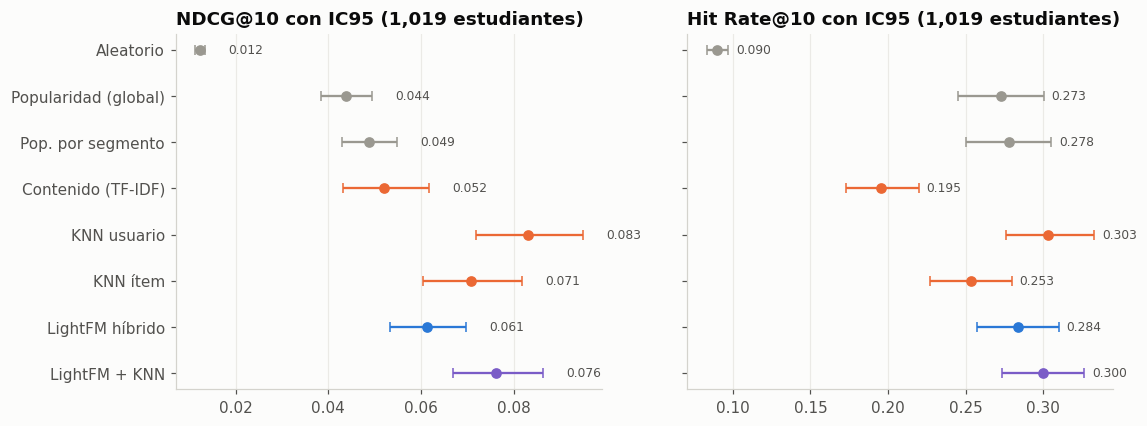

In [13]:
if HAY_DATOS:
    def color_de(n_):
        if n_ == "Aleatorio" or n_.startswith("Pop"): return GRIS
        if n_ == "LightFM + KNN": return VIOLETA
        return AZUL if "LightFM" in n_ else NARANJA
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
    y = np.arange(len(orden))[::-1]
    for ax, met, tit in zip(axes, ["ndcg", "hit_rate"], ["NDCG@10", "Hit Rate@10"]):
        for yi, n_ in zip(y, orden):
            mu, lo, hi = ex.ic_bootstrap(dets[n_].query("K == 10")[met].values)
            ax.errorbar(mu, yi, xerr=[[mu - lo], [hi - mu]], fmt="o", color=color_de(n_), ecolor=color_de(n_), capsize=3, ms=6)
            ax.text(hi + 0.005, yi, f"{mu:.3f}", va="center", fontsize=8, color=TXT2)
        ax.set_title(f"{tit} con IC95 ({len(eleg):,} estudiantes)"); ax.grid(axis="y", visible=False)
    axes[0].set_yticks(y, orden)
    guardar(fig, "27_mooc_ic_modelos"); plt.show()

### ¿Cuánto aportan los atributos a LightFM? (ablación)

Misma partición y mismos hiperparámetros, pero con LightFM **sin atributos** (factorización pura, solo con el historial). Es la prueba directa de si ahora LightFM tiene con qué trabajar: en RutaPro simulado, quitarle los atributos lo hundía.

In [14]:
if HAY_DATOS:
    fab_sin = lambda s: rr.LightFMHibrido(**hp["lfm"], usar_atributos=False, seed=s)
    det_sin, _ = ex.evaluar_semillas(fab_sin, prueba, semillas=[42, 43, 44, 45, 46])
    abl = ex.tabla_con_ic({"LightFM con atributos": dets["LightFM híbrido"], "LightFM sin atributos": det_sin,
                           "Popularidad (global)": dets["Popularidad (global)"]}, K=10)[["estudiantes", "ndcg", "ndcg IC95", "hit_rate", "hit_rate IC95"]]
    abl.to_csv(RES / "ablacion_atributos_lightfm.csv")
    display(abl.round(3))
    dif = ex.comparar_pareado(dets["LightFM híbrido"], det_sin, K=10)
    print("Con atributos − sin atributos (NDCG@10):", {k_: round(float(v), 4) for k_, v in dif.items()})

,estudiantes,ndcg,ndcg IC95,hit_rate,hit_rate IC95
modelo,,,,,
LightFM con atributos,1019,0.061,"[0.053, 0.070]",0.284,"[0.258, 0.310]"
LightFM sin atributos,1019,0.055,"[0.048, 0.062]",0.228,"[0.212, 0.245]"
Popularidad (global),1019,0.044,"[0.038, 0.049]",0.273,"[0.245, 0.300]"


Con atributos − sin atributos (NDCG@10): {'dif. media': 0.0063, 'IC95 inf': -0.0017, 'IC95 sup': 0.0142, 'mejora': 277.0, 'empeora': 359.0, 'p (Wilcoxon)': 0.8044}


## 5. Pruebas pareadas (Wilcoxon, bootstrap y Holm)

Dos referencias, como en RutaPro: la popularidad global y la popularidad por segmento. Con miles de estudiantes la diferencia mínima detectable es mucho menor que con 133, así que **ahora sí se pueden distinguir diferencias pequeñas**: conviene mirar el tamaño de la diferencia y no solo el p-valor.

In [15]:
if HAY_DATOS:
    def familia(base, cands, K=10):
        t = pd.DataFrame({n_: ex.comparar_pareado(dets[n_], dets[base], K=K) for n_ in cands}).T
        t["p ajustado (Holm)"] = ex.holm(t["p (Wilcoxon)"].astype(float))
        t["¿significativo al 5 %?"] = np.where(t["p ajustado (Holm)"] < 0.05, "sí", "no")
        return t
    cands_A = [n_ for n_ in orden if n_ not in ("Aleatorio", "Popularidad (global)")]
    cands_B = [n_ for n_ in orden if n_ not in ("Aleatorio", "Popularidad (global)", "Pop. por segmento")]
    res_p = {}
    for K in (10, 5):
        res_p[f"A. frente a Popularidad global · K={K}"] = familia("Popularidad (global)", cands_A, K)
        res_p[f"B. frente a Pop. por segmento · K={K}"] = familia("Pop. por segmento", cands_B, K)
        if HIB:                                   # C: híbrido MENOS cada componente (positivo = el híbrido mejora)
            comp_ = ["LightFM híbrido", "KNN usuario", "KNN ítem"]
            tC = pd.DataFrame({n_: ex.comparar_pareado(dets["LightFM + KNN"], dets[n_], K=K) for n_ in comp_}).T
            tC["p ajustado (Holm)"] = ex.holm(tC["p (Wilcoxon)"].astype(float))
            tC["¿significativo al 5 %?"] = np.where(tC["p ajustado (Holm)"] < 0.05, "sí", "no")
            res_p[f"C. LightFM + KNN menos cada componente (positivo = el híbrido mejora) · K={K}"] = tC
    for nombre, t in res_p.items():
        t.to_csv(RES / ("pruebas_" + nombre.split(".")[0] + "_k" + nombre.split("=")[-1] + ".csv"))
        print(nombre); display(t.round(4))
    def mde(a_, b_):
        d_ = (dets[a_].query("K == 10").set_index("user_id")["ndcg"] - dets[b_].query("K == 10").set_index("user_id")["ndcg"])
        return 2.8 * d_.std(ddof=1) / np.sqrt(len(d_)), len(d_)
    m1, n1 = mde("LightFM híbrido", "Pop. por segmento")
    print(f"Diferencia mínima detectable (LightFM vs Pop. por segmento; potencia 80 %, nivel 5 %): ≈ {m1:.4f} de NDCG@10 con {n1:,} estudiantes")
    if HIB:
        m2, n2 = mde("LightFM + KNN", "KNN usuario")
        print(f"Diferencia mínima detectable (LightFM + KNN vs KNN usuario): ≈ {m2:.4f} de NDCG@10 con {n2:,} estudiantes")

A. frente a Popularidad global · K=10


,dif. media,IC95 inf,IC95 sup,mejora,empeora,p (Wilcoxon),p ajustado (Holm),¿significativo al 5 %?
Pop. por segmento,0.0050,0.0014,0.0086,208.0,128.0,0.0020,0.0061,sí
Contenido (TF-IDF),0.0083,-0.0013,0.0186,160.0,235.0,0.1209,0.1209,no
KNN usuario,0.0392,0.0285,0.0507,254.0,193.0,0.0000,0.0000,sí
KNN ítem,0.0270,0.0163,0.0385,217.0,216.0,0.0114,0.0227,sí
LightFM híbrido,0.0176,0.0111,0.0244,273.0,186.0,0.0001,0.0003,sí
LightFM + KNN,0.0324,0.0237,0.0416,274.0,201.0,0.0000,0.0000,sí


B. frente a Pop. por segmento · K=10


,dif. media,IC95 inf,IC95 sup,mejora,empeora,p (Wilcoxon),p ajustado (Holm),¿significativo al 5 %?
Contenido (TF-IDF),0.0033,-0.0065,0.0139,157.0,243.0,0.0261,0.0522,no
KNN usuario,0.0342,0.0234,0.0454,246.0,171.0,0.0000,0.0000,sí
KNN ítem,0.0219,0.0110,0.0337,207.0,227.0,0.1413,0.1413,no
LightFM híbrido,0.0125,0.0065,0.0189,257.0,161.0,0.0007,0.0020,sí
LightFM + KNN,0.0274,0.0189,0.0364,264.0,184.0,0.0000,0.0001,sí


C. LightFM + KNN menos cada componente (positivo = el híbrido mejora) · K=10


...

B. frente a Pop. por segmento · K=5


,dif. media,IC95 inf,IC95 sup,mejora,empeora,p (Wilcoxon),p ajustado (Holm),¿significativo al 5 %?
Contenido (TF-IDF),0.0018,-0.0081,0.0121,105.0,163.0,0.2751,0.2751,no
KNN usuario,0.0337,0.0225,0.0457,178.0,126.0,0.0000,0.0000,sí
KNN ítem,0.0203,0.0094,0.0318,153.0,155.0,0.0358,0.1074,no
LightFM híbrido,0.0082,0.0015,0.0152,176.0,116.0,0.0666,0.1332,no
LightFM + KNN,0.0218,0.0127,0.0314,191.0,134.0,0.0003,0.0013,sí


C. LightFM + KNN menos cada componente (positivo = el híbrido mejora) · K=5


,dif. media,IC95 inf,IC95 sup,mejora,empeora,p (Wilcoxon),p ajustado (Holm),¿significativo al 5 %?
LightFM híbrido,0.0136,0.0057,0.0223,151.0,138.0,0.0052,0.0104,sí
KNN usuario,-0.0120,-0.0203,-0.0037,123.0,155.0,0.0033,0.0098,sí
KNN ítem,0.0015,-0.0061,0.0089,150.0,105.0,0.4958,0.4958,no


Diferencia mínima detectable (LightFM vs Pop. por segmento; potencia 80 %, nivel 5 %): ≈ 0.0088 de NDCG@10 con 1,019 estudiantes
Diferencia mínima detectable (LightFM + KNN vs KNN usuario): ≈ 0.0099 de NDCG@10 con 1,019 estudiantes


## 6. ¿Importa el esquema de partición? (con datos reales)

En RutaPro se comprobó, con datos simulados, que la fuga del esquema por estudiante no alteraba el orden de los modelos. Aquí se repite con datos reales.

In [16]:
if HAY_DATOS:
    filas = []
    for esq in ("global", "usuario"):
        dd, tab_, n_ev = ex.evaluar_dataset(cur, usu, inter, None, esq, hp, seg_cols=SEG, con_reglas=False, ngram_cont=(1, 2))
        filas.append(tab_["ndcg"].rename(f"NDCG@10 · corte {esq} (n={n_ev:,})"))
    comp = pd.concat(filas, axis=1)
    comp["cambio relativo (usuario vs global)"] = 100 * (comp.iloc[:, 1] / comp.iloc[:, 0] - 1)
    display(comp.round(3))
    from scipy import stats
    print("Correlación de Spearman entre los dos órdenes de modelos:", round(stats.spearmanr(comp.iloc[:, 0], comp.iloc[:, 1])[0], 2))
    comp.to_csv(RES / "esquema_global_vs_usuario.csv")

,"NDCG@10 · corte global (n=1,019)","NDCG@10 · corte usuario (n=3,714)",cambio relativo (usuario vs global)
modelo,,,
Popularidad,0.044,0.068,54.355
Pop. por segmento,0.049,0.069,40.665
Contenido (TF-IDF),0.052,0.097,85.640
KNN usuario,0.083,0.147,77.730
KNN ítem,0.071,0.140,97.427
LightFM híbrido,0.060,0.083,38.782
LightFM + KNN,0.077,0.130,68.923


Correlación de Spearman entre los dos órdenes de modelos: 0.93


## 7. Cold start sin trampa (estudiantes retenidos fuera de todo el entrenamiento)

Mismo protocolo del notebook 05: protocolo **A** (estudiante nuevo realista: se evalúan todas sus inscripciones) y **B** (mismos candidatos y objetivos que con historial). Como el perfil real es pobre (género, escuela, cohorte), se espera **menos** ventaja del perfil que en RutaPro. El contenido no participa (sin texto del estudiante) y **el híbrido LightFM + KNN tampoco**: KNN necesita historial, así que para un estudiante nuevo el híbrido se reduce a LightFM.

En la primera ejecución la ganancia de LightFM venía del código de género, pero el baseline por segmento usaba la escuela (por la tolerancia mal escalada). Aquí el rival correcto es **Pop. por género**: se incluye siempre.

In [17]:
if HAY_DATOS:
    SEM = [42, 43, 44]
    FORM = {"completo (género, escuela, cohorte)": ("genero", "escuela", "edad"), "solo escuela": ("escuela",), "solo género y cohorte": ("genero", "edad")}
    folds = ex.pliegues_usuarios(eleg, n_pliegues=5, seed=0)
    acum = {"A": {}, "B": {}}
    for k, fuera in enumerate(folds):
        d_fit = ex.particion_cold_start(cur, usu, pares, fuera, esquema=ESQ, objetivo="test")
        d_eval = {"A": ex.particion_cold_start(cur, usu, pares, fuera, esquema=ESQ, objetivo="todo"), "B": prueba}
        assert not (set(d_fit.train.user_id) & fuera)
        pop_s = rr.Popularidad().fit(d_fit).puntajes(None)
        seg_f = ex.PopularidadSegmento(SEG, hp["seg_m"]).fit(d_fit)
        base = {"Popularidad (global)": ex.SoloPerfil(lambda p: pop_s, perfil_de),
                "Pop. por segmento": ex.SoloPerfil(seg_f.puntajes_perfil, perfil_de)}
        if SEG != ("genero",):
            seg_g = ex.PopularidadSegmento(("genero",), hp["seg_m"]).fit(d_fit)
            base["Pop. por género"] = ex.SoloPerfil(seg_g.puntajes_perfil, perfil_de)
        for pr in ("A", "B"):
            for n_, m_ in base.items():
                acum[pr].setdefault(n_, []).append(rr.evaluar(m_, d_eval[pr], ks=(5, 10), usuarios=sorted(fuera), devolver_detalle=True)[1])
        for sd in SEM:
            lfm = rr.LightFMHibrido(**hp["lfm"], seed=sd).fit(d_fit)
            for etiqueta, pref in FORM.items():
                fn = (lambda p, lfm=lfm, pref=pref: ex.puntajes_cold_filtrado(lfm, p, pref))
                for pr in ("A", "B"):
                    acum[pr].setdefault("LightFM · " + etiqueta, {}).setdefault(sd, []).append(
                        rr.evaluar(ex.SoloPerfil(fn, perfil_de), d_eval[pr], ks=(5, 10), usuarios=sorted(fuera), devolver_detalle=True)[1])
        print(f"pliegue {k + 1}/{len(folds)} listo")
    DETC = {"A": {}, "B": {}}
    for pr in ("A", "B"):
        for n_, v in acum[pr].items():
            DETC[pr][n_] = ex.promediar_det([pd.concat(x) for x in v.values()]) if isinstance(v, dict) else pd.concat(v)
    DETC["B"]["Referencia: LightFM CON historial"] = dets["LightFM híbrido"]
    for pr, tit in [("A", "A. Estudiante nuevo realista"), ("B", "B. Mismos candidatos y objetivos que con historial")]:
        for K in (10, 5):
            t = ex.tabla_con_ic(DETC[pr], K=K)[["estudiantes", "ndcg", "ndcg IC95", "hit_rate", "hit_rate IC95"]]
            t.to_csv(RES / f"cold_start_{pr}_k{K}.csv"); print(f"{tit} · K = {K}"); display(t.round(3))
    ADOP = "LightFM · completo (género, escuela, cohorte)"
    rivales = [n_ for n_ in ("Pop. por segmento", "Pop. por género") if n_ in DETC["A"]]
    for K in (10, 5):
        t = pd.DataFrame({n_: ex.comparar_pareado(DETC["A"][n_], DETC["A"]["Popularidad (global)"], K=K) for n_ in [ADOP] + rivales}).T
        t["p ajustado (Holm)"] = ex.holm(t["p (Wilcoxon)"].astype(float)); print(f"A · frente a la popularidad global · K={K}"); display(t.round(4))
        for rv in rivales:                       # la prueba que decide: ¿gana LightFM al rival simple por el mismo segmento?
            t = ex.comparar_pareado(DETC["A"][ADOP], DETC["A"][rv], K=K)
            print(f"A · {ADOP} − {rv} · K={K}:", {k_: round(float(v), 4) for k_, v in t.items()})
        t = ex.comparar_pareado(DETC["B"][ADOP], DETC["B"]["Referencia: LightFM CON historial"], K=K)
        print(f"B · diferencia (sin historial − con historial) · K={K}; negativo = lo que se pierde por no tener historial:", {k_: round(float(v), 4) for k_, v in t.items()})

pliegue 1/5 listo
pliegue 2/5 listo
pliegue 3/5 listo
pliegue 4/5 listo
pliegue 5/5 listo
A. Estudiante nuevo realista · K = 10


,estudiantes,ndcg,ndcg IC95,hit_rate,hit_rate IC95
modelo,,,,,
Popularidad (global),1019,0.130,"[0.121, 0.138]",0.670,"[0.641, 0.699]"
Pop. por segmento,1019,0.173,"[0.163, 0.182]",0.747,"[0.720, 0.771]"
"LightFM · completo (género, escuela, cohorte)",1019,0.208,"[0.197, 0.219]",0.766,"[0.740, 0.791]"
LightFM · solo escuela,1019,0.148,"[0.139, 0.158]",0.615,"[0.586, 0.642]"
LightFM · solo género y cohorte,1019,0.200,"[0.190, 0.211]",0.745,"[0.718, 0.771]"


A. Estudiante nuevo realista · K = 5


,estudiantes,ndcg,ndcg IC95,hit_rate,hit_rate IC95
modelo,,,,,
Popularidad (global),1019,0.133,"[0.122, 0.143]",0.518,"[0.488, 0.549]"
Pop. por segmento,1019,0.153,"[0.142, 0.164]",0.559,"[0.529, 0.588]"
"LightFM · completo (género, escuela, cohorte)",1019,0.212,"[0.199, 0.225]",0.633,"[0.605, 0.662]"
LightFM · solo escuela,1019,0.160,"[0.148, 0.172]",0.489,"[0.460, 0.519]"
LightFM · solo género y cohorte,1019,0.201,"[0.189, 0.214]",0.613,"[0.585, 0.641]"


B. Mismos candidatos y objetivos que con historial · K = 10


...

A · frente a la popularidad global · K=10


,dif. media,IC95 inf,IC95 sup,mejora,empeora,p (Wilcoxon),p ajustado (Holm)
"LightFM · completo (género, escuela, cohorte)",0.0781,0.0697,0.0865,623.0,196.0,0.0,0.0
Pop. por segmento,0.0429,0.0375,0.0485,559.0,184.0,0.0,0.0


A · LightFM · completo (género, escuela, cohorte) − Pop. por segmento · K=10: {'dif. media': 0.0352, 'IC95 inf': 0.0295, 'IC95 sup': 0.0408, 'mejora': 539.0, 'empeora': 261.0, 'p (Wilcoxon)': 0.0}
B · diferencia (sin historial − con historial) · K=10; negativo = lo que se pierde por no tener historial: {'dif. media': -0.0025, 'IC95 inf': -0.0092, 'IC95 sup': 0.0038, 'mejora': 212.0, 'empeora': 234.0, 'p (Wilcoxon)': 0.6561}
A · frente a la popularidad global · K=5


,dif. media,IC95 inf,IC95 sup,mejora,empeora,p (Wilcoxon),p ajustado (Holm)
"LightFM · completo (género, escuela, cohorte)",0.0790,0.0676,0.0903,514.0,197.0,0.0,0.0
Pop. por segmento,0.0207,0.0156,0.0259,386.0,168.0,0.0,0.0


A · LightFM · completo (género, escuela, cohorte) − Pop. por segmento · K=5: {'dif. media': 0.0583, 'IC95 inf': 0.0488, 'IC95 sup': 0.0676, 'mejora': 479.0, 'empeora': 215.0, 'p (Wilcoxon)': 0.0}
B · diferencia (sin historial − con historial) · K=5; negativo = lo que se pierde por no tener historial: {'dif. media': 0.0055, 'IC95 inf': -0.0022, 'IC95 sup': 0.0128, 'mejora': 152.0, 'empeora': 153.0, 'p (Wilcoxon)': 0.1319}


## 8. Sesgos y equidad con datos reales

Sesgo de popularidad (concentración de la exposición) y desempeño por grupo. Con datos reales los grupos son grandes: aquí las diferencias entre grupos **sí** pueden ser concluyentes.

In [18]:
if HAY_DATOS:
    mods_exp = {n_: recs[n_] for n_ in ["Popularidad (global)", "Pop. por segmento", "Contenido (TF-IDF)", "KNN usuario", "KNN ítem", "LightFM híbrido", "LightFM + KNN"] if n_ in recs}
    expo = pd.DataFrame({n_: ex.exposicion(r, prueba) for n_, r in mods_exp.items()}).T
    expo.to_csv(RES / "exposicion.csv"); print("Concentración de la exposición (Top-10)"); display(expo.round(2))

    n_hist = prueba.train[prueba.train.positivo == 1].groupby("user_id").size()
    info = usu.set_index("user_id").loc[eleg].copy()
    info["historial"] = pd.cut(n_hist.reindex(info.index), [0, 2, 5, 10, 10_000], labels=["1-2", "3-5", "6-10", ">10"]).astype(str)
    top_esc = info.escuela.value_counts().head(8).index
    info["escuela_top"] = np.where(info.escuela.isin(top_esc), info.escuela, "otras")
    info = info.reset_index()
    grupos = {}
    for col in ["genero", "edad_grupo", "historial", "escuela_top"]:
        tabs = {}
        for n_ in [n_ for n_ in ["Popularidad (global)", "Pop. por segmento", "KNN usuario", "LightFM híbrido", "LightFM + KNN"] if n_ in dets]:
            dd = dets[n_].query("K == 10").merge(info[["user_id", col]], on="user_id")
            tabs[n_] = dd.groupby(col)["ndcg"].mean()
        t = pd.DataFrame(tabs); t["estudiantes"] = info.groupby(col).size()
        t["LightFM − Pop.segmento"] = t["LightFM híbrido"] - t["Pop. por segmento"]
        grupos[col] = t; print(f"NDCG@10 por {col}"); display(t.round(3))
    pd.concat(grupos, names=["variable", "grupo"]).to_csv(RES / "equidad_por_grupo.csv")

Concentración de la exposición (Top-10)


,cobertura,Gini de exposición,% recs en el 20 % más popular
Popularidad (global),0.03,0.98,100.00
Pop. por segmento,0.06,0.98,100.00
Contenido (TF-IDF),0.76,0.82,35.67
KNN usuario,0.65,0.82,83.51
KNN ítem,0.90,0.63,55.74
LightFM híbrido,0.29,0.92,95.34
LightFM + KNN,0.69,0.83,83.54


NDCG@10 por genero


,Popularidad (global),Pop. por segmento,KNN usuario,LightFM híbrido,LightFM + KNN,estudiantes,LightFM − Pop.segmento
genero,,,,,,,
g0,0.039,0.044,0.060,0.052,0.055,678,0.009
g1,0.051,0.058,0.133,0.091,0.124,214,0.034
g2,0.055,0.061,0.123,0.058,0.107,127,-0.003


NDCG@10 por edad_grupo


,Popularidad (global),Pop. por segmento,KNN usuario,LightFM híbrido,LightFM + KNN,estudiantes,LightFM − Pop.segmento
edad_grupo,,,,,,,
1980-1989,0.000,0.000,0.500,0.058,0.358,1,0.058
sin_dato,0.044,0.049,0.083,0.061,0.076,1018,0.012


NDCG@10 por historial


,Popularidad (global),Pop. por segmento,KNN usuario,LightFM híbrido,LightFM + KNN,estudiantes,LightFM − Pop.segmento
historial,,,,,,,
1-2,0.050,0.052,0.130,0.077,0.105,154,0.025
3-5,0.041,0.052,0.179,0.098,0.163,133,0.046
6-10,0.054,0.050,0.085,0.057,0.087,95,0.007
>10,0.041,0.047,0.051,0.051,0.049,637,0.003


NDCG@10 por escuela_top


,Popularidad (global),Pop. por segmento,KNN usuario,LightFM híbrido,LightFM + KNN,estudiantes,LightFM − Pop.segmento
escuela_top,,,,,,,
otra,0.045,0.047,0.131,0.082,0.124,147,0.035
sin_dato,0.044,0.049,0.072,0.056,0.066,857,0.007
清华大学,0.025,0.041,0.242,0.160,0.209,15,0.119


## 9. Sensibilidad al tamaño de la muestra

¿Cuántos estudiantes hacen falta para que las conclusiones se estabilicen? (RutaPro tenía 133 evaluables.) Se repite el protocolo con muestras de distinto tamaño y 3 muestras por tamaño.

modelo,Contenido (TF-IDF),KNN usuario,KNN ítem,LightFM + KNN,LightFM híbrido,Pop. por segmento,Popularidad
N,,,,,,,
500,0.077,0.073,0.063,0.068,0.056,0.049,0.048
1000,0.051,0.070,0.060,0.074,0.053,0.050,0.039
2000,0.055,0.078,0.065,0.076,0.054,0.048,0.039
5000,0.055,0.080,0.077,0.080,0.060,0.047,0.039


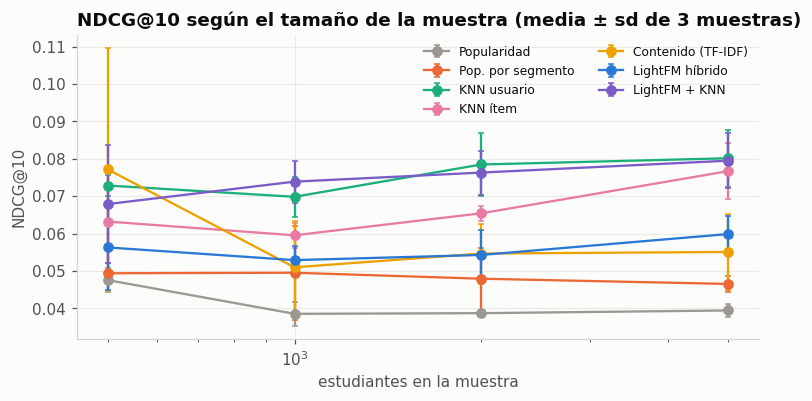

In [19]:
if HAY_DATOS:
    filas = []
    for N in sorted({500, 1000, 2000, N_USUARIOS}):
        for rep in range(3):
            mp = max(5, int(MIN_POP_CURSO * N / N_USUARIOS))
            u_n, c_n, i_n, _ = mc.preparar(usuarios_raw, ins_raw, cursos_raw, n_usuarios=N, seed=100 + rep, min_pop_curso=mp, min_inscripciones=MIN_INSCRIPCIONES)
            try:
                _, tab_, n_ev = ex.evaluar_dataset(c_n, u_n, i_n, None, ESQ, hp, seg_cols=SEG, con_reglas=False, ngram_cont=(1, 2))
            except Exception as e:      # muestras muy pequeñas pueden dejar pocas particiones
                print("N =", N, "rep", rep, "omitida:", repr(e)[:80]); continue
            for m_, r_ in tab_.iterrows():
                filas.append({"N": N, "rep": rep, "modelo": m_, "ndcg": r_.ndcg, "evaluables": n_ev})
    sens = pd.DataFrame(filas); sens.to_csv(RES / "sensibilidad_tamano.csv", index=False)
    piv = sens.groupby(["N", "modelo"]).ndcg.agg(["mean", "std"]).unstack("modelo")
    display(piv["mean"].round(3))
    fig, ax = plt.subplots(figsize=(8, 3.6))
    cols_m = {"Popularidad": GRIS, "Pop. por segmento": NARANJA, "KNN usuario": AQUA, "KNN ítem": MAGENTA, "Contenido (TF-IDF)": AMARILLO,
              "LightFM híbrido": AZUL, "LightFM + KNN": VIOLETA}
    for m_, c_ in cols_m.items():
        if m_ in piv["mean"]:
            ax.errorbar(piv.index, piv["mean"][m_], yerr=piv["std"][m_].fillna(0), color=c_, marker="o", capsize=2, label=m_)
    ax.set_xscale("log"); ax.set_xlabel("estudiantes en la muestra"); ax.set_ylabel("NDCG@10"); ax.set_title("NDCG@10 según el tamaño de la muestra (media ± sd de 3 muestras)")
    ax.legend(frameon=False, fontsize=8, ncol=2); guardar(fig, "28_mooc_sensibilidad_tamano"); plt.show()

## 10. ¿Y si todos los estudiantes tienen perfil?

Si la mayoría de los estudiantes no informa su escuela ni su año de nacimiento, los modelos que dependen del perfil (LightFM y la popularidad por segmento) están en desventaja **por falta de datos, no por falta de método**. Aquí se repite la evaluación en dos poblaciones: todos los estudiantes, y **solo los que tienen escuela o cohorte informada**. Se usan los mismos hiperparámetros y el mismo protocolo, de modo que la diferencia entre columnas se debe a la población.

> Ojo: quienes completan su perfil pueden comportarse distinto (más comprometidos, por ejemplo), así que esta comparación mezcla dos efectos: más información del perfil y otro tipo de estudiante. Se reporta como sensibilidad, no como causa.

In [20]:
if HAY_DATOS:
    filas = []
    for etiqueta, solo in [("Todos los estudiantes", False), ("Solo con escuela o cohorte informada", True)]:
        u_p, c_p, i_p, r_p = mc.preparar(usuarios_raw, ins_raw, cursos_raw, n_usuarios=N_USUARIOS, seed=11, min_pop_curso=MIN_POP_CURSO,
                                         min_inscripciones=MIN_INSCRIPCIONES, solo_con_perfil=solo)
        try:
            _, tab_p, n_ev = ex.evaluar_dataset(c_p, u_p, i_p, None, ESQ, hp, seg_cols=SEG, con_reglas=False, ngram_cont=(1, 2))
        except Exception as e:          # una población muy pequeña puede no dejar particiones
            print(etiqueta, "omitida:", repr(e)[:100]); continue
        pr = mc.resumen_atributos(u_p)
        print(f"{etiqueta}: {len(u_p):,} estudiantes, {len(c_p):,} cursos, {n_ev:,} evaluables, "
              f"{pr['% con escuela o cohorte informada']:.0f} % con escuela o cohorte")
        for m_, r_ in tab_p.iterrows():
            filas.append({"población": etiqueta, "modelo": m_, "ndcg": r_.ndcg})
    pob = pd.DataFrame(filas)
    if len(pob):
        piv = pob.pivot(index="modelo", columns="población", values="ndcg")
        rel = piv / piv.loc["Popularidad"]
        sal = pd.concat({"NDCG@10": piv, "relativo a la popularidad": rel}, axis=1)
        sal.to_csv(RES / "poblacion_con_perfil.csv")
        display(sal.round(3))

Todos los estudiantes: 3,818 estudiantes, 743 cursos, 1,029 evaluables, 22 % con escuela o cohorte
Solo con escuela o cohorte informada: 2,834 estudiantes, 321 cursos, 628 evaluables, 100 % con escuela o cohorte


NDCG@10                        \
población          Solo con escuela o cohorte informada Todos los estudiantes   
modelo                                                                          
Contenido (TF-IDF)                                0.151                 0.049   
KNN usuario                                       0.195                 0.083   
KNN ítem                                          0.218                 0.072   
LightFM + KNN                                     0.211                 0.076   
LightFM híbrido                                   0.144                 0.062   
Pop. por segmento                                 0.060                 0.050   
Popularidad                                       0.052                 0.040   

                              relativo a la popularidad                        
población          Solo con escuela o cohorte informada Todos los estudiantes  
modelo                                                                         
Contenido (TF-IDF)                                2.880                 1.228  
KNN usuario                                       3.709                 2.077  
KNN ítem                                          4.145                 1.803  
LightFM + KNN                                     4.029                 1.897  
LightFM híbrido                                   2.748                 1.544  
Pop. por segmento                                 1.150                 1.264  
Popularidad                                       1.000                 1.000

## 11. Comparación con RutaPro (simulado) y con la primera ejecución sin atributos

Para comparar conjuntos de datos distintos se usa el **NDCG@10 relativo a la popularidad global** (las escalas absolutas no son comparables). Los valores de RutaPro vienen del notebook 04 (NDCG@10: popularidad 0.134, por segmento + reglas 0.183, contenido 0.126, KNN usuario 0.129, KNN ítem 0.130, LightFM + reglas 0.195). La columna *MOOCCube v1* recoge los valores de la **primera ejecución de este notebook, con MOOCCube v1 y sin atributos**.

> **Cuidado al leerla:** las tres columnas son **conjuntos de datos y muestras distintas**. Sirven para comparar el *orden* de los modelos, no para atribuir diferencias a los atributos. El efecto de los atributos sobre LightFM se mide solo con la **ablación** (sección 4), que usa la misma muestra con y sin atributos. Por eso esta versión ya no incluye una columna de "cambio por tener atributos".

In [21]:
if HAY_DATOS:
    rutapro = pd.Series({"Popularidad (global)": 0.134, "Pop. por segmento": 0.183, "Contenido (TF-IDF)": 0.126, "KNN usuario": 0.129,
                         "KNN ítem": 0.130, "LightFM híbrido": 0.195}) / 0.134
    v1_sin_atributos = pd.Series({"Popularidad (global)": 1.00, "Pop. por segmento": 1.00, "Contenido (TF-IDF)": 1.92, "KNN usuario": 1.45,
                                  "KNN ítem": 1.56, "LightFM híbrido": 1.11})
    mooc = t10["ndcg"] / t10.loc["Popularidad (global)", "ndcg"]
    mooc = mooc.drop("Aleatorio", errors="ignore")
    cmp_ = pd.DataFrame({"RutaPro (simulado)": rutapro, "MOOCCube v1 real (sin atributos)": v1_sin_atributos,
                         "MOOCCubeX real (con atributos, v2)": mooc}).reindex(mooc.index)
    cmp_.to_csv(RES / "comparacion_rutapro_vs_real.csv")
    display(cmp_.round(2).astype(object).where(cmp_.notna(), "—"))
    print("Orden de los modelos (de mejor a peor):")
    for col in cmp_.columns:
        print(f" {col}:", " > ".join(cmp_[col].dropna().sort_values(ascending=False).index))

,RutaPro (simulado),MOOCCube v1 real (sin atributos),"MOOCCubeX real (con atributos, v2)"
modelo,,,
Popularidad (global),1.0,1.0,1.0
Pop. por segmento,1.37,1.0,1.12
Contenido (TF-IDF),0.94,1.92,1.19
KNN usuario,0.96,1.45,1.9
KNN ítem,0.97,1.56,1.62
LightFM híbrido,1.46,1.11,1.4
LightFM + KNN,—,—,1.74


Orden de los modelos (de mejor a peor):
 RutaPro (simulado): LightFM híbrido > Pop. por segmento > Popularidad (global) > KNN ítem > KNN usuario > Contenido (TF-IDF)
 MOOCCube v1 real (sin atributos): Contenido (TF-IDF) > KNN ítem > KNN usuario > LightFM híbrido > Pop. por segmento > Popularidad (global)
 MOOCCubeX real (con atributos, v2): KNN usuario > LightFM + KNN > KNN ítem > LightFM híbrido > Contenido (TF-IDF) > Pop. por segmento > Popularidad (global)


## 12. Qué concluir según lo que salga (guía de lectura; no contiene resultados)

Estas reglas se fijan **antes** de ver los resultados para no interpretarlos a conveniencia.

| Si en los datos reales ocurre… | Entonces se puede concluir… |
|---|---|
| LightFM supera a la popularidad global y a la popularidad por segmento con diferencias mayores que la diferencia mínima detectable | La ventaja del híbrido **sí aparece con comportamiento real**; el hallazgo de RutaPro (ventaja no robusta frente a personalización simple) se debía en parte al simulador |
| LightFM ≈ popularidad por segmento | Se confirma el hallazgo de RutaPro: **la personalización simple captura casi todo**; defender LightFM por cobertura y cold start, no por precisión |
| KNN o contenido superan a LightFM | Hay **señal colaborativa o de historial real** que el simulador del v1 no tenía (como el escenario E4); respalda la mejora futura "combinar LightFM con historial" |
| La popularidad global es difícil de superar (NDCG relativo cerca de 1) | Datos con **mucha concentración**: típico de MOOC; el sesgo de popularidad es un riesgo real, y la cobertura pasa a ser el criterio clave |
| El cold start por perfil (género, escuela, cohorte) no supera a la popularidad | El perfil real es **demasiado pobre**: para RutaPro hay que pedir más datos en el formulario (objetivo, nivel, intereses), cosa que MOOCCubeX no permite probar |
| El orden de los modelos coincide con RutaPro | Evidencia a favor de que **las conclusiones del simulador se trasladan** (con las reservas de que cambian dominio, idioma y atributos) |
| El orden cambia | Las conclusiones de RutaPro **dependen del simulador**; decirlo explícitamente en la defensa |
| LightFM **con** atributos supera claramente a LightFM **sin** atributos (ablación) | Los atributos reales aportan: en MOOCCube v1 el modelo estaba limitado por falta de insumo, no por el método |
| LightFM con atributos **sigue por debajo** de contenido o KNN | Con comportamiento real el **historial pesa más que un perfil pobre** (género, escuela y cohorte, con muchos vacíos), aunque el perfil esté disponible; la mejora futura "combinar LightFM con historial" queda respaldada |
| La popularidad por segmento supera a la global ahora que hay segmentos | El perfil, aun pobre, **sí segmenta**; la personalización simple ya aporta algo con datos reales |
| Con estudiantes que sí informan perfil (sección 10) LightFM y el segmento mejoran respecto de "todos" | Parte de la desventaja anterior era **falta de datos de perfil**, no del método (con la reserva de que quienes completan su perfil pueden ser otro tipo de estudiante) |
| **El híbrido LightFM + KNN supera a LightFM y a ambos KNN** (familia C de la sección 5) | La combinación **sí aprovecha** señales distintas (historial de KNN y estructura de LightFM): la mejora futura propuesta queda confirmada con datos reales |
| El híbrido **iguala** al mejor KNN (diferencia no significativa) | LightFM **no agrega** señal sobre KNN con estos datos; la mejora no se confirma y el modelo sencillo (KNN) basta |
| El híbrido queda **por debajo** del mejor KNN | El peso de LightFM elegido en validación no generaliza; revisar la rejilla de `w` antes de concluir nada |
| Con tolerancia relativa LightFM mejora respecto de la primera ejecución | La conclusión anterior sobre LightFM estaba **subestimada por la configuración**, no por el método; compararlo con la tabla de la v1 de este notebook |
| En el cold start, LightFM **no supera** a Pop. por género | La ganancia del cold start venía de que el código de género segmenta, no de LightFM; un segmento simple basta |
| Las diferencias entre grupos (género, cohorte, escuela) son grandes con n alto | Hay un **riesgo de equidad** real que documentar en la Fase 7 |

**Reservas que deben acompañar cualquier conclusión:** (1) es otra plataforma, país, idioma y público que RutaPro; (2) no existen nivel, idioma ni objetivo laboral, así que se prueba un subconjunto del sistema (sin reglas ni oráculo); (3) se analiza una muestra aleatoria del 5 % de los estudiantes y luego `N_USUARIOS` tras el filtro k-core, que descarta cursos y estudiantes poco activos; (3b) el peso del híbrido y los hiperparámetros se eligen en validación con tolerancia relativa del 5 %, y no se sabe qué significa el código de género (g0, g1, g2); (4) un estudiante de MOOCCubeX elige entre ~miles de cursos de muchas disciplinas, no entre 107 cursos de datos.

## 13. Para el informe

Tabla principal con IC95 (`tabla_principal_k10.csv`), pruebas pareadas, cold start A y B, esquema global frente a usuario, equidad, sensibilidad al tamaño (figura 28), la ablación de atributos, el híbrido LightFM + KNN frente a sus componentes, la población con perfil y la comparación con RutaPro y con la ejecución sin atributos. Redacta una conclusión de una sola frase por cada fila de la tabla anterior que se cumpla, con su cifra.

In [22]:
if HAY_DATOS:
    mc.restaurar_adaptadores()
    print("Resultados guardados en", RES.relative_to(BASE))
    for p in sorted(RES.iterdir()): print(" -", p.name)

Resultados guardados en 02_Notebooks/resultados_mooc
 - ablacion_atributos_lightfm.csv
 - atributos_informados.csv
 - cold_start_A_k10.csv
 - cold_start_A_k5.csv
 - cold_start_B_k10.csv
 - cold_start_B_k5.csv
 - comparacion_rutapro_vs_real.csv
 - descripcion_datos_reales.csv
 - equidad_por_grupo.csv
 - esquema_global_vs_usuario.csv
 - exposicion.csv
 - grid_segmento.csv
 - hiperparametros_mooc.json
 - poblacion_con_perfil.csv
 - pruebas_A_k10.csv
 - pruebas_A_k5.csv
 - pruebas_B_k10.csv
 - pruebas_B_k5.csv
 - pruebas_C_k10.csv
 - pruebas_C_k5.csv
 - sensibilidad_tamano.csv
 - tabla_principal_k10.csv
 - tabla_principal_k5.csv
